In [25]:
# If the import doesn't work, uncomment the following two lines, or "pip install thunor"
import os, sys
#sys.path.insert(0, os.path.abspath('../'))

import thunor
import re
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

from thunor.io import read_vanderbilt_hts
from thunor.dip import dip_rates
from thunor.curve_fit import fit_params
from thunor.curve_fit import fit_params_minimal
from thunor.plots import plot_drc, plot_drc_params, plot_time_course, plot_ctrl_dip_by_plate, plot_plate_map

In [60]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output"))
DATADIR = Path(os.path.expanduser("~/ECM_mod_output"))
SAVEFILES = True
OVERWRITE = True

### Import cell counts

In [37]:
f = open(SAVEDIR / 'cell_counts_di_4kpa_erl.json')
cell_counts_di_4erl = json.load(f)

In [12]:
f = open(SAVEDIR / 'cell_counts_di_55kpa_erl.json')
cell_counts_di_55erl = json.load(f)

In [13]:
EXPT_ID = 1
EXPT_DATE = '2023-11-21'
PLATE_NAME = 'test'
CELL_LINE = 'DS8'
DRUG1 = 'cycdi'
DRUG1_UNITS = 'M'
UPID = 'test'
df_columns = ['expt.id', 'expt.date', 'plate.name', 'well', 'cell.line', 'time', 'drug1', 'drug1.conc', 'drug1.units', 'cell.count', 'upid']


In [14]:
WELLS = []
for c in list(map(chr,range(ord('A'),ord('M')+1))):
    tmp_lst = [c+"{:02d}".format(num) for num in range(1,6)]
    WELLS.append(tmp_lst)
WELLS = [x for xs in WELLS for x in xs]

In [15]:
all_treats = pd.DataFrame(columns = df_columns)


In [16]:
def add_cond(allDF, cell_counts, drug="drug1"):
    n=0
    for cond in cell_counts:
        for run in cell_counts[cond]:
            tmp_t = [point[0] for point in run]
            tmp_c = [point[1] for point in run]
            
            tmp_dict = {'expt.id': [EXPT_ID] * len(tmp_t),
                        'expt.date': [EXPT_DATE] * len(tmp_t),
                        'plate.name': [PLATE_NAME] * len(tmp_t),
                        'well': [WELLS[n]] * len(tmp_t),
                        'cell.line': [CELL_LINE] * len(tmp_t),
                        'time': tmp_t,
                        'drug1': [drug] * len(tmp_t),
                        'drug1.conc': [float(cond)*10e-7] * len(tmp_t),
                        'drug1.units': [DRUG1_UNITS] * len(tmp_t),
                        'cell.count': tmp_c,
                        'upid': [UPID] * len(tmp_t)
                       }
            tmp_df = pd.DataFrame(tmp_dict)
            df_r = tmp_df.loc[tmp_df['time'] <= 120]
            df_r = df_r.round({'time': 3})
            df_r = df_r.drop_duplicates(subset=['time'])
            
            n+=1
            allDF = pd.concat([allDF, df_r], ignore_index=True)
    return allDF
    
            

In [41]:
def calc_resp(filepath, cond, drug, wells=WELLS):
    f = open(filepath)
    cell_counts = json.load(f)
    name = cond

    EXPT_ID = 1
    EXPT_DATE = '2023-11-21'
    PLATE_NAME = 'test'
    CELL_LINE = 'DS8'
    DRUG1 = 'cycdi'
    DRUG1_UNITS = 'M'
    UPID = 'test'
    df_columns = ['expt.id', 'expt.date', 'plate.name', 'well', 'cell.line', 'time', 'drug1', 'drug1.conc', 'drug1.units', 'cell.count', 'upid']

    all_treats = pd.DataFrame(columns = df_columns)
    
    all_treats = add_cond(all_treats, cell_counts, drug=drug)
    name_c = name + '.csv'
    path = SAVEDIR / name_c
    all_treats.to_csv(path, index=False)
    
    hts = read_vanderbilt_hts(str(path))
    
    ctrl_dip_data, expt_dip_data = dip_rates(hts)
    fp = fit_params(ctrl_dip_data, expt_dip_data)
    return fp, ctrl_dip_data, expt_dip_data

In [19]:
def add_plot(cell_count, run_time, fig, ax, title="Unknown condition", color="black", ls='-'):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    pop_dubs = np.log2(cell_count_t / cell_count_t[0])
    ax.plot(t_sim, pop_dubs, color=color, lw=1, alpha=0.8, ls=ls)

    return

In [20]:
def make_fig(cell_count, run_time, title="Unknown condition"):
    fig, ax = plt.subplots()
    
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Population doublings')
    ax.set_ylim(0,5)
    plt.text(0,4.5,title)
    
    return fig, ax

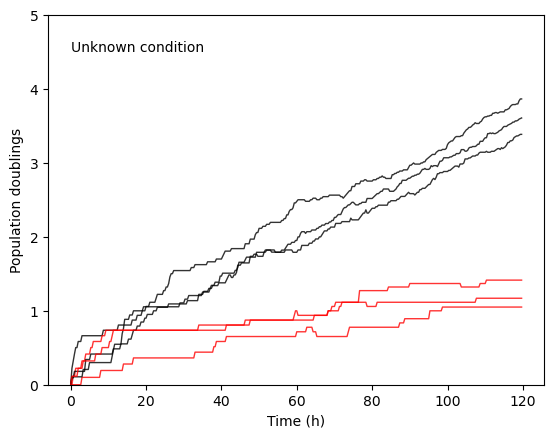

In [21]:
fig,ax = make_fig(cell_counts_di_55erl['0'][0], 120, title="Unknown condition")
for ii in range(3):
    add_plot(cell_counts_di_55erl['0'][ii], 120, fig, ax, title="Unknown condition", color="black")
#     add_plot(cell_counts_di_55erl['0.1'][ii], 120, fig, ax, title="Unknown condition", color="blue")
    add_plot(cell_counts_di_55erl['0.4'][ii], 120, fig, ax, title="Unknown condition", color="red")
    

In [26]:
# filepaths = os.listdir(DATADIR)
# filenames = [f for f in filepaths if re.search('^cell_counts.*csv$', f)]
# filepaths = [Path(DATADIR, f) for f in filenames]
# filepaths.sort()

### CycDi 55kPa ERL

In [42]:
filepath = SAVEDIR / 'cell_counts_di_55kpa_erl.json'
cond = 'di_55kpa_erl'
# filepath = 'C:\\Users\\olesk\\ECM_mod_output\\cell_counts_di_55kpa_erl.json'

WindowsPath('C:/Users/olesk/ECM_mod_output/cell_counts_di_55kpa_erl.json')

In [43]:
fp, ctrl_dip_data, expt_dip_data = calc_resp(filepath, cond, 'cycdi', wells=WELLS)

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning: invalid value encountered in log
  return c + (d - c) / (1 + np.exp(b * (np.log(x) - np.log(e))))


In [44]:
df_params = fit_params_minimal(ctrl_dip_data, expt_dip_data)

C:\Users\olesk\anaconda3\envs\ECM_model\lib\site-packages\thunor\curve_fit.py:157: RuntimeWarning: invalid value encountered in log
  return c + (d - c) / (1 + np.exp(b * (np.log(x) - np.log(e))))


In [52]:
fig = plot_drc(fp)

In [54]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)
import matplotlib.offsetbox as offsetbox

In [57]:
def plot_dipplt(fig=fig, fp=fp):
    fig1 = plt.figure()
    ax = fig1.add_subplot(1,1,1)
    
    mean_untreated = np.mean(fig.data[2]['y'])
    norm_treated = [num/mean_untreated for num in fig.data[1]['y']]
    
    line, = ax.plot(fig.data[0]['x'], fig.data[0]['y'], color='red')
    pts = ax.scatter(fig.data[1]['x'], norm_treated, color='black')
    
    
    
    ob = offsetbox.AnchoredText(f'EC50: {fp["ec50"].iloc[0]:.2e} M \nIC50: {fp["ic50"].iloc[0]:.2e} M', loc=3, prop=dict(size=16))
    # ax.text(1, 0.5, f'EC50: {fp["ec50"].iloc[0]:.2e} M', ha='center')
    ax.add_artist(ob)
    
    ax.set_xlim(0.4e-9, 1e-5)
    ax.set_xscale('log')
    # ax.xaxis.set_tick_params(labelbottom=False)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize= 22)
#     ax.set_xlabel('CycDi [M]')
    ax.set_ylabel('Relative DIP Rate', fontsize=22)
    return fig1
    

C:\Users\olesk\AppData\Local\Temp\ipykernel_52640\4245081353.py:20: UserWarning:

FixedFormatter should only be used together with FixedLocator



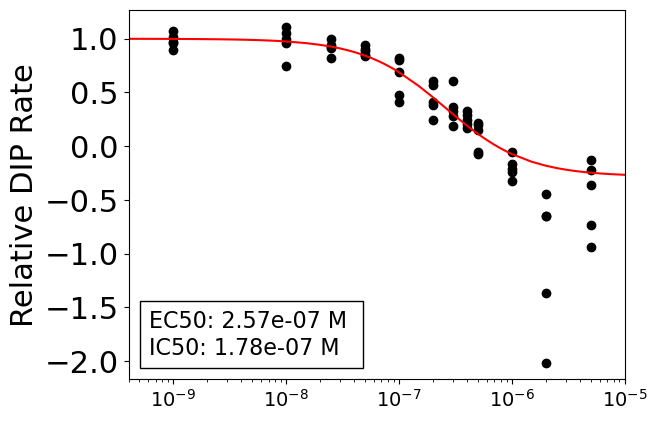

In [61]:
figure = plot_dipplt(fig=fig, fp=fp)

filepath = Path(SAVEDIR,'fig7B_doseresponse.png')
if SAVEFILES and (not filepath.exists() or OVERWRITE):
    plt.savefig(filepath, format='png', dpi=300)